# Question 9: where are lower-income ZIPs seeing the fastest price growth?

A ZIP is under **price pressure** when its 2015 median household income was below the median of its metro's ZIPs and
its home value growth from the 2015 average to the latest 12 months was in the top fifth of its metro. Source:
`gold.mart_zip_month` (Zillow ZHVI, ACS 5-year ZIP income through the ZCTA with the same code); ZIP outlines from
`data/export/zip_shapes.geojson` (`.\tasks.ps1 export`).

Caveats: this is an association, not displacement. Price growth says nothing about who moved out, and cheaper homes
grew faster everywhere in this period (Q5), so low-income ZIPs are expected to be over-represented in the top fifth.
ZIP income is a five-year pooled estimate: the 2015 value covers 2011-2015 and the latest the 2020-2024 vintage, so
recent changes in who lives there show up late. ZIPs with no ZHVI in 2015 or no ACS income are left out.

In [1]:
import json

import common as c
import numpy as np
from matplotlib.collections import PolyCollection

In [2]:
z = c.q(
    """
    with z as (
        select zip, cbsa_code,
            avg(zhvi_usd) filter (year(month) = 2015) v0,
            avg(zhvi_usd) filter (month > $latest - interval 12 month and month <= $latest) v1,
            avg(median_household_income_usd) filter (year(month) = 2015) y0,
            avg(median_household_income_usd) filter (month > $latest - interval 12 month and month <= $latest) y1
        from gold.mart_zip_month group by all
    ), g as (
        select *, v1 / v0 - 1 growth, y1 / y0 - 1 income_growth from z
        where v0 is not null and v1 is not null and y0 is not null
    )
    select *,
        percent_rank() over (partition by cbsa_code order by growth) growth_rank,
        y0 < median(y0) over (partition by cbsa_code) low_income
    from g
    """,
    {"latest": c.LATEST},
)
z["top_growth"] = z.growth_rank >= 0.8
z["pressure"] = z.low_income & z.top_growth
z["metro"] = z.cbsa_code.map(c.METRO)
by = z.groupby("metro").agg(
    zips=("zip", "size"),
    top_growth=("top_growth", "sum"),
    pressure=("pressure", "sum"),
    low_income_share_of_top=(
        "low_income",
        lambda s: s[z.loc[s.index, "top_growth"]].mean(),
    ),
)
by.sort_values("low_income_share_of_top", ascending=False)

,zips,top_growth,pressure,low_income_share_of_top
metro,,,,
Atlanta,197,40,40,1.000
Orlando,89,18,18,1.000
Dallas-Fort Worth,245,49,49,1.000
Raleigh,45,9,9,1.000
Phoenix,145,29,28,0.966
Tampa,128,26,25,0.962
Charlotte,104,21,20,0.952
Austin,83,17,12,0.706
Denver,120,24,16,0.667


In [3]:
# income growth since 2015 (ACS 5-year) in pressure ZIPs against the metro's other low-income ZIPs
inc = z[z.low_income].groupby(["metro", "pressure"]).income_growth.median().unstack()
inc.columns = ["other_low_income", "pressure"]
inc["gap"] = inc.pressure - inc.other_low_income
inc.sort_values("gap", ascending=False)

,other_low_income,pressure,gap
metro,,,
Phoenix,0.595,0.816,0.220
Orlando,0.553,0.694,0.141
Nashville,0.631,0.711,0.080
Seattle,0.643,0.705,0.062
Dallas-Fort Worth,0.526,0.576,0.050
Charlotte,0.513,0.536,0.022
Denver,0.629,0.631,0.002
Tampa,0.600,0.586,-0.014
Atlanta,0.593,0.535,-0.058


In [4]:
top3 = (
    z[z.pressure]
    .sort_values("growth", ascending=False)
    .groupby("metro")
    .head(3)[["metro", "zip", "y0", "v0", "v1", "growth", "income_growth"]]
    .sort_values(["metro", "growth"], ascending=[True, False])
)
top3

,metro,zip,y0,v0,v1,growth,income_growth
745,Atlanta,30314,25291.875,39997.592,225568.272,4.640,0.664
744,Atlanta,30310,25916.708,68505.766,262633.407,2.834,1.046
743,Atlanta,30274,38151.375,62120.710,203231.475,2.272,0.368
186,Austin,78616,51941.292,156583.032,360386.287,1.302,0.246
185,Austin,78650,57586.792,212534.888,454453.015,1.138,0.479
183,Austin,78612,60844.083,200948.546,425591.666,1.118,0.570
103,Charlotte,28208,29286.583,85027.376,295673.508,2.477,0.893
102,Charlotte,28206,25722.708,95406.749,327497.319,2.433,1.403
101,Charlotte,28217,41388.417,105202.386,323931.380,2.079,0.547
1402,Dallas-Fort Worth,75212,30193.208,73448.301,243413.899,2.314,0.979


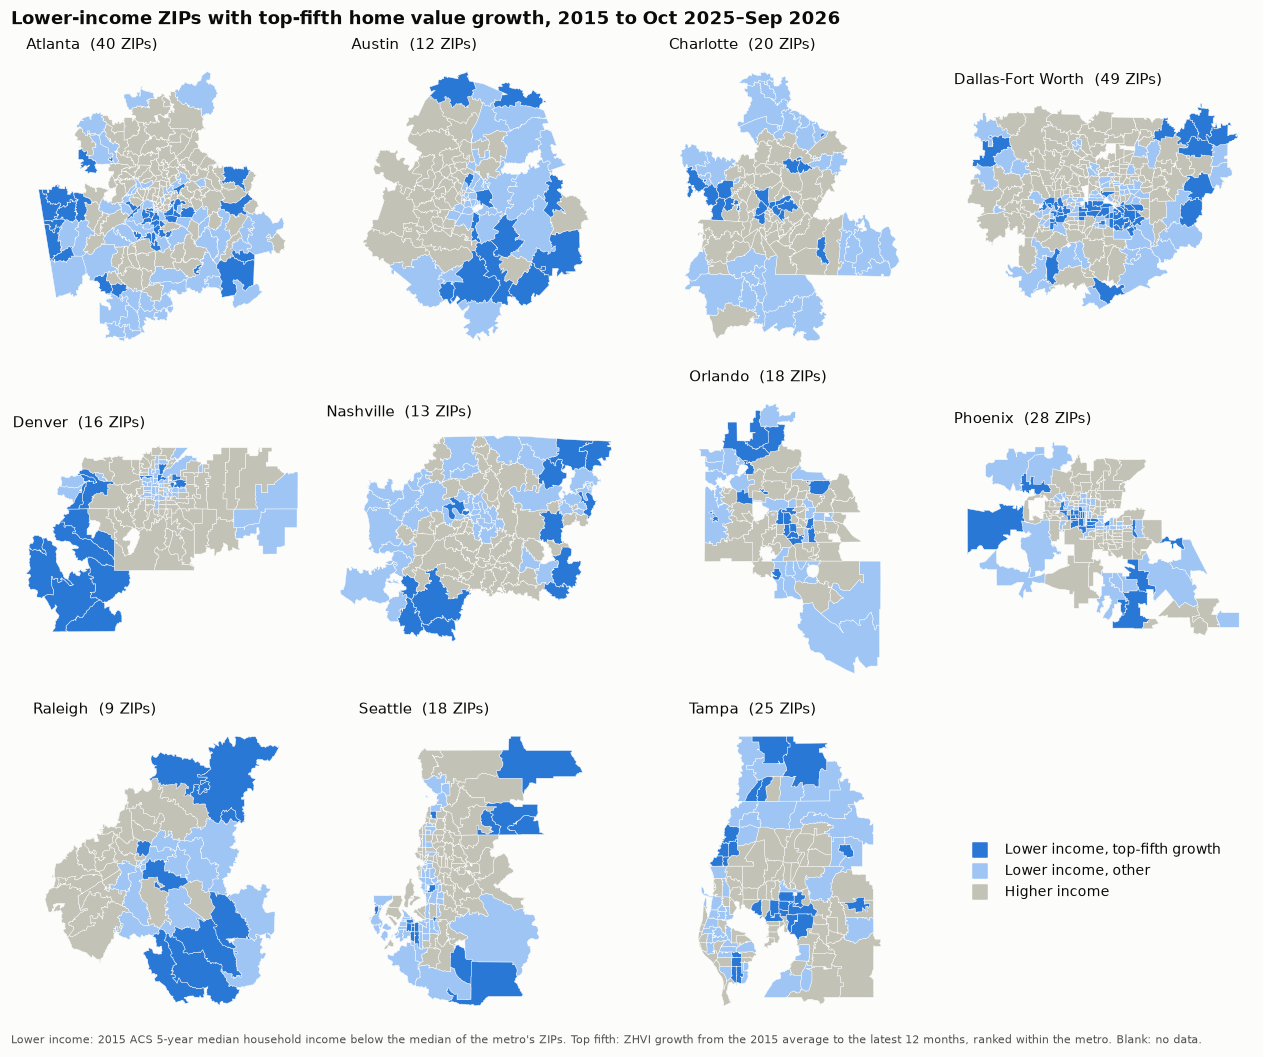

In [5]:
shapes = json.loads((c.ROOT / "data" / "export" / "zip_shapes.geojson").read_text())
rings = {}
for f in shapes["features"]:
    g = f["geometry"]
    polys = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    rings[f["properties"]["zip"]] = [p[0] for p in polys]
color = {
    zz: c.BLUE if p else ("#9ec5f4" if lo else c.MUTED)
    for zz, p, lo in zip(z.zip, z.pressure, z.low_income)
}
fig, axes = c.plt.subplots(3, 4, figsize=(12, 9.5))
for ax, (code_, metro) in zip(axes.flat, c.METRO.sort_values().items()):
    zips = [zz for zz in z.zip[z.cbsa_code == code_] if zz in rings]
    polys = [r for zz in zips for r in rings[zz]]
    ax.add_collection(
        PolyCollection(
            polys,
            facecolors=[color[zz] for zz in zips for _ in rings[zz]],
            edgecolors=c.SURFACE,
            linewidths=0.3,
        )
    )
    ax.autoscale_view()
    ax.set_aspect(
        1 / np.cos(np.radians(np.mean([pt[1] for r in polys[:50] for pt in r])))
    )
    ax.set_title(f"{metro}  ({by.loc[metro, 'pressure']} ZIPs)")
    ax.axis("off")
legend = axes.flat[-1]
legend.axis("off")
for col, label in (
    (c.BLUE, "Lower income, top-fifth growth"),
    ("#9ec5f4", "Lower income, other"),
    (c.MUTED, "Higher income"),
):
    legend.scatter([], [], s=80, marker="s", color=col, label=label)
legend.legend(loc="center left", frameon=False)
c.save(
    fig,
    "q9_price_pressure_maps",
    f"Lower-income ZIPs with top-fifth home value growth, 2015 to {c.LATEST_12M}",
    "Lower income: 2015 ACS 5-year median household income below the median of the metro's ZIPs. Top fifth: ZHVI "
    "growth from the 2015 average to the latest 12 months, ranked within the metro. Blank: no data.",
)

## Answer

In [6]:
share = z[z.top_growth].low_income.mean()
print(
    f"{int(z.pressure.sum())} of {len(z)} ZIPs are lower-income ZIPs with top-fifth growth. Of each metro's top-fifth "
    f"growth ZIPs, {share:.0%} were below the metro's median income in 2015 (50% if growth ignored income); by metro "
    f"{by.low_income_share_of_top.min():.0%} ({by.low_income_share_of_top.idxmin()}) to "
    f"{by.low_income_share_of_top.max():.0%} ({by.low_income_share_of_top.idxmax()})."
)
print(
    f"Median ACS income growth since 2015: {z[z.pressure].income_growth.median():+.0%} in pressure ZIPs against "
    f"{z[z.low_income & ~z.top_growth].income_growth.median():+.0%} in other lower-income ZIPs and "
    f"{z[~z.low_income].income_growth.median():+.0%} in higher-income ZIPs."
)

248 of 1403 ZIPs are lower-income ZIPs with top-fifth growth. Of each metro's top-fifth growth ZIPs, 88% were below the metro's median income in 2015 (50% if growth ignored income); by metro 60% (Seattle) to 100% (Atlanta).
Median ACS income growth since 2015: +62% in pressure ZIPs against +60% in other lower-income ZIPs and +49% in higher-income ZIPs.
